# Introduction

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from datetime import datetime

# Chargement des données
x_train = pd.read_csv("../data/x_train_clean.csv")
y_train = pd.read_csv("../data/y_train_clean.csv")
x_test = pd.read_csv("../data/x_test_clean.csv")

SEED = 42 # graine aléatoire 
rng = np.random.default_rng(SEED)

# Les 4 postes, du plus bas au plus haut dans la hiérarchie
postes = ["Assistant", "Executive", "Manager", "Director"]


---
# Partie 1 — Statistiques sur les données

On charge les 3 fichiers et on vérifie que les données sont correctes.

D'après l'énoncé, on s'attend à environ **29 000 carrières** dans le train et **7 000** dans le test. On vérifie également que x_train et x_test ont le même nombre de colonnes.

In [109]:
print(f"x_train : {x_train.shape[0]:6d} lignes, {x_train.shape[1]:5d} colonnes")
print(f"y_train : {y_train.shape[0]:6d} lignes, {y_train.shape[1]:5d} colonnes")
print(f"x_test : {x_test.shape[0]:6d} lignes, {x_test.shape[1]:5d} colonnes")

x_train :  29273 lignes,    65 colonnes
y_train :  29273 lignes,     3 colonnes
x_test :   7327 lignes,    65 colonnes


On regarde les premières lignes des 3 fichiers pour vérifier rapidement qu'il n'y a pas de problème sur les données.

In [110]:
print("x_train:")
display(x_train.head())

print("y_train :")
display(y_train.head())

print("x_test:")
display(x_test.head())

x_train:


,id,employee_feature_0,employee_feature_1,employee_feature_2,employee_feature_3,employee_feature_4,employee_feature_5,employee_feature_6,employee_feature_7,employee_feature_8,...,company_feature_22,company_feature_23,company_feature_24,company_feature_25,company_feature_26,company_feature_27,company_feature_28,company_feature_29,company_feature_30,company_feature_31
0,0,0.013263,-0.376167,-0.613827,0.359729,0.193883,0.388050,-0.001953,-0.019567,0.161783,...,0.496415,-0.295326,0.294123,0.566333,-0.450409,0.667816,-0.907596,-0.421868,-0.320554,-0.404289
1,1,-0.282738,-0.012908,0.205368,0.482457,0.285612,-0.261424,0.602928,-0.176004,0.351918,...,0.534470,-0.209862,0.664622,0.539178,-0.367445,0.639607,-0.869631,-0.154816,0.075938,-0.639021
2,2,0.399990,-0.298473,-0.210973,-0.032957,0.057687,0.421141,0.949937,-0.365188,0.327099,...,0.125662,0.140065,0.080729,0.233294,-0.238041,0.564176,-0.930845,-0.559797,0.103106,-0.149208
3,3,0.399990,-0.298473,-0.210973,-0.032957,0.057687,0.421141,0.949937,-0.365188,0.327099,...,0.413645,-0.109720,0.322721,0.508323,-0.369104,0.496631,-0.881074,-0.056100,0.556903,-0.202640
4,4,0.010124,0.057610,-0.121743,0.057732,0.084081,-0.044404,0.155736,-0.125136,0.237426,...,0.416849,0.408343,0.337121,0.392495,-0.265649,0.664976,-0.922024,-0.505522,-0.364163,-0.073651


y_train :


,id,position,target
0,0,Executive,1
1,1,Executive,1
2,2,Executive,1
3,3,Executive,1
4,4,Executive,1


x_test:


,id,employee_feature_0,employee_feature_1,employee_feature_2,employee_feature_3,employee_feature_4,employee_feature_5,employee_feature_6,employee_feature_7,employee_feature_8,...,company_feature_22,company_feature_23,company_feature_24,company_feature_25,company_feature_26,company_feature_27,company_feature_28,company_feature_29,company_feature_30,company_feature_31
0,29273,0.770294,-0.147882,0.486307,0.389991,-0.450313,-0.526806,0.998577,0.304267,0.073247,...,0.521330,0.350061,0.162991,0.504313,-0.371429,0.675732,-0.967248,-0.196321,0.080971,-0.336691
1,29274,0.340061,0.550675,-0.273903,0.265983,-0.219236,0.081678,0.179793,-0.025414,0.186707,...,0.521330,0.350061,0.162991,0.504313,-0.371429,0.675732,-0.967248,-0.196321,0.080971,-0.336691
2,29275,-0.038707,0.139382,0.114205,-0.258506,0.239997,0.411867,0.133353,-0.058503,0.151351,...,0.441937,0.111995,0.694086,0.436403,-0.137214,0.280484,-0.921925,-0.216101,-0.433705,0.196600
3,29276,-0.038707,0.139382,0.114205,-0.258506,0.239997,0.411867,0.133353,-0.058503,0.151351,...,0.312529,0.038193,-0.368810,0.342731,-0.081778,0.667781,-0.930811,-0.222494,-0.186185,-0.379813
4,29277,0.021639,-0.399257,-0.742458,0.633686,0.082964,0.399026,0.496338,-0.032831,0.067287,...,0.441937,0.111995,0.694086,0.436403,-0.137214,0.280484,-0.921925,-0.216101,-0.433705,0.196600


On vérifie qu'il n'y a pas de valeurs manquantes dans les données (NaN, valeurs nulles, ...).

In [111]:
manquantes = pd.Series({
    "x_train": int(x_train.isna().sum().sum()),
    "y_train": int(y_train.isna().sum().sum()),
    "x_test": int(x_test.isna().sum().sum()),
})
print(manquantes.to_string())

x_train    0
y_train    0
x_test     0


On analyse la répartition entre les 4 postes à partir de y_train.


Type de la cible                : str
Nombre de classes (réel)        : 4
Postes hors des 4 postes prévus : aucun


,effectif,part (%),rang (fréquence),rapport vs majoritaire
position,,,,
Assistant,9023,30.8,2,0.51
Executive,17793,60.8,1,1.00
Manager,1101,3.8,4,0.06
Director,1356,4.6,3,0.08



--- Indicateurs de déséquilibre ---
Classe majoritaire              : Executive (60.8 %)
Classe minoritaire              : Manager (3.8 %)
Ratio majoritaire / minoritaire : 16.2

--- Niveaux de référence ---
Accuracy d'un classifieur majoritaire : 60.8 %
Accuracy d'un tirage uniforme         : 25.0 %
F1 macro d'un classifieur majoritaire : 0.189


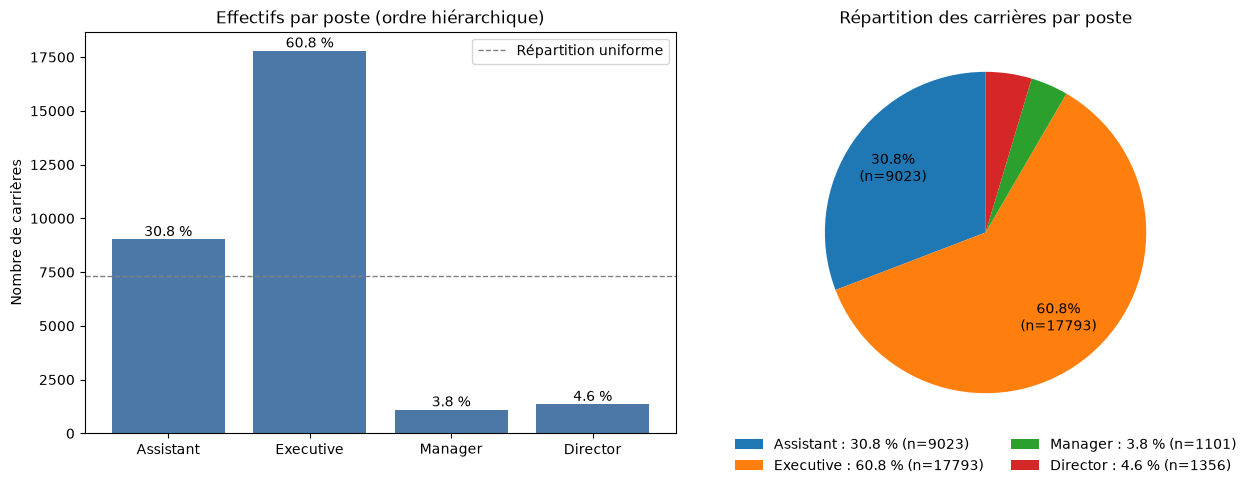

In [112]:
colonne_position = y_train.columns[1]
y = y_train[colonne_position]

# 1. Contrôles de qualité des postes
print(f"Type de la cible                : {y.dtype}")
print(f"Nombre de classes (réel)        : {y.nunique()}")
print(f"Postes hors des 4 postes prévus : {set(y.dropna().unique()) - set(postes) or 'aucun'}")

# 2. Tableau des effectifs 
effectifs = y.value_counts().reindex(postes, fill_value=0)
total = effectifs.sum()
parts = effectifs / total * 100

tableau = pd.DataFrame({
    "effectif": effectifs,
    "part (%)": parts.round(1),
    "rang (fréquence)": effectifs.rank(ascending=False, method="min").astype(int),
    "rapport vs majoritaire": (effectifs / effectifs.max()).round(2),
})
display(tableau)


# 3. Indicateurs de déséquilibre
K = len(postes)

# a voir si on utilise ???
#---------------------------------------------------------------------------------------
#p = effectifs[effectifs > 0] / total
#entropie = -(p * np.log(p)).sum()
#entropie_norm = entropie / np.log(K)          # 1 = parfaitement équilibré
#nb_classes_effectif = np.exp(entropie)        # nb de classes "équivalentes"
#gini_simpson = 1 - (p ** 2).sum()
#chi2, pval = chisquare(effectifs)             # H0 : répartition uniforme
#---------------------------------------------------------------------------------------


print("\n--- Indicateurs de déséquilibre ---")
print(f"Classe majoritaire              : {effectifs.idxmax()} ({parts.max():.1f} %)")
print(f"Classe minoritaire              : {effectifs.idxmin()} ({parts.min():.1f} %)")
if effectifs.min() > 0:
    print(f"Ratio majoritaire / minoritaire : {effectifs.max() / effectifs.min():.1f}")
#print(f"Écart absolu max - min          : {parts.max() - parts.min():.1f} points")
#print(f"Entropie normalisée (0-1)       : {entropie_norm:.3f}")
#print(f"Nombre effectif de classes      : {nb_classes_effectif:.2f} sur {K}")
#print(f"Indice de Gini-Simpson          : {gini_simpson:.3f}")
#print(f"Test du χ² vs uniforme          : χ²={chi2:.1f}, p-value={pval:.3g}")

print("\n--- Niveaux de référence ---")
print(f"Accuracy d'un classifieur majoritaire : {parts.max():.1f} %")
print(f"Accuracy d'un tirage uniforme         : {100 / K:.1f} %")
print(f"F1 macro d'un classifieur majoritaire : "
      f"{(2 * (parts.max()/100) / (1 + parts.max()/100)) / K:.3f}")

# 4. Graphiques : barres (ordre hiérarchique) + Pareto
fig, (ax_bar, ax_pie) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})

ax_bar.bar(effectifs.index, effectifs.values, color="#4C78A8")
for i, (n, pt) in enumerate(zip(effectifs.values, parts.values)):
    ax_bar.text(i, n, f"{pt:.1f} %", ha="center", va="bottom")  # pourcentage au-dessus de chaque barre
ax_bar.axhline(total / K, color="grey", ls="--", lw=1, label="Répartition uniforme")
ax_bar.set(title="Effectifs par poste (ordre hiérarchique)", ylabel="Nombre de carrières")
ax_bar.legend()


ax_pie.pie(
    effectifs,
    autopct=lambda pc: f"{pc:.1f}%\n(n={int(round(pc * total / 100))})" if pc >= 10 else "",
    startangle=90,
    pctdistance=0.7,
)
ax_pie.legend(
    [f"{poste} : {pt:.1f} % (n={n})" for poste, pt, n in zip(effectifs.index, parts, effectifs)],
    loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False,
)
ax_pie.set_title("Répartition des carrières par poste")

plt.tight_layout()
plt.show()

On fait une analyse rapide des embeddings pour voir si on les lit bien et si on ne trouve pas de grosses incohérences.

In [113]:
def separer_embeddings(df):
    emp = [f'employee_feature_{i}' for i in range(32)]
    comp = [f'company_feature_{i}' for i in range(32)]

    return df[emp].to_numpy(float), df[comp].to_numpy(float)


def resume(M):
    """Statistiques descriptives d'une matrice d'embeddings (une ligne = un vecteur)."""
    normes = np.linalg.norm(M, axis=1)
    n_distincts = len(np.unique(M.round(6), axis=0))
    return {
        "dimensions": M.shape[1],
        "valeurs manquantes": int(np.isnan(M).sum()),
        "moyenne": round(M.mean(), 3),
        "écart-type": round(M.std(), 3),
        "norme moyenne": round(normes.mean(), 3),
        "vecteurs distincts": n_distincts,
        "part de doublons (%)": round(100 * (1 - n_distincts / len(M)), 1),
    }


employe_train, company_train = separer_embeddings(x_train)
employe_test, company_test = separer_embeddings(x_test)

bilan = pd.DataFrame.from_dict({
    "employé (train)": resume(employe_train),
    "entreprise (train)": resume(company_train),
    "employé (test)": resume(employe_test),
    "entreprise (test)": resume(company_test),
}, orient="index")
display(bilan)




,dimensions,valeurs manquantes,moyenne,écart-type,norme moyenne,vecteurs distincts,part de doublons (%)
employé (train),32,0,0.010,0.500,2.815,17841,39.1
entreprise (train),32,0,0.003,0.502,2.826,4378,85.0
employé (test),32,0,0.012,0.500,2.811,5985,18.3
entreprise (test),32,0,0.007,0.498,2.797,615,91.6


---
# Partie 2 — Soumission aléatoire

On compare d'abord le F1 macro d'un tirage uniforme et d'un tirage qui respecte la répartition des classes du train (moyenne sur 100 répétitions).



In [114]:
proba_uniforme = np.full(len(postes), 1 / len(postes))
proba_repartie = (effectifs / effectifs.sum()).values

def score_hasard(probabilites, repetitions=100):
    scores = []
    for _ in range(repetitions):
        prediction = rng.choice(postes, size=len(y), p=probabilites)
        scores.append(f1_score(y, prediction, average="macro", labels=postes, zero_division=0))
    return np.mean(scores), np.std(scores)

for nom, probas in [("Tirage uniforme", proba_uniforme), ("Tirage selon le train", proba_repartie)]:
    moyenne, ecart = score_hasard(probas)
    print(f"{nom:24s} F1 macro = {moyenne:.3f} (± {ecart:.3f})")


Tirage uniforme          F1 macro = 0.194 (± 0.002)
Tirage selon le train    F1 macro = 0.250 (± 0.002)


On génère un fichier de soumission à partir du tirage qui respecte la répartition des classes, car c'est celui qui obtient le meilleur F1 macro ci-dessus.

In [115]:
def fabriquer_soumission(probabilites, nom_fichier):
    exemple = pd.read_csv("../data/y_test_exemple.csv")
    soumission = exemple[["id", "position"]].copy()
    soumission["position"] = rng.choice(postes, size=len(soumission), p=probabilites)

    chemin = f"../submissions/{nom_fichier}"

    soumission.to_csv(chemin , index=True)
    return soumission, chemin

horodatage = datetime.now().strftime("%d-%m_%H-%M")
soumission_aleatoire, chemin = fabriquer_soumission(proba_repartie, f"random_submission_{horodatage}.csv")

print("Fichier créé :")
print(f"  {chemin}  ({len(soumission_aleatoire)} lignes)")
display(pd.read_csv(chemin).head())

Fichier créé :
  ../submissions/random_submission_28-10_20-09.csv  (7327 lignes)


,Unnamed: 0,id,position
0,0,29273,Executive
1,1,29274,Executive
2,2,29275,Executive
3,3,29276,Executive
4,4,29277,Executive
